# 03 — Exploratory data analysis: magnitudes, Gutenberg-Richter, time, depth, space

This notebook is the scientific core of Week 1. It characterises the processed catalog
(707,438 earthquakes, 2000-01-01 → 2026-11-15) and estimates the parameters that
later stages will lean on — above all the **b-value** of the Gutenberg-Richter law.

**Scientific stance (non-negotiable):**
* This project *estimates probabilities from history*; it does **not** predict when or
  where the next earthquake will happen.
* **Historical activity is not disaster risk** — a dense record of past events says
  nothing by itself about exposure, vulnerability or impact.
* **Catalog completeness varies by region and by era**: absence of records is not
  absence of seismicity.
* Every claim below is backed by a number computed in this notebook.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap

# The build tool executes the kernel with cwd = notebooks/; move to the repository root
# so every relative path below follows the documented repo-root convention.
if not Path("data").exists():
    os.chdir(Path.cwd().parent)
assert Path("data/processed/earthquakes.parquet").exists(), "run from the repository root"

NAVY = "#14263D"
ACCENT = "#2583A6"
LIGHT = "#E9EEF3"

plt.rcParams.update(
    {
        "figure.figsize": (9, 5),
        "figure.dpi": 150,
        "savefig.dpi": 150,
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "axes.edgecolor": NAVY,
        "axes.labelcolor": NAVY,
        "text.color": NAVY,
        "xtick.color": NAVY,
        "ytick.color": NAVY,
        "axes.grid": True,
        "grid.color": LIGHT,
        "axes.axisbelow": True,
        "legend.frameon": False,
        "savefig.bbox": "tight",
        "savefig.facecolor": "white",
    }
)

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name: str) -> Path:
    """Write reports/figures/<name>, embed it in the notebook, free the memory."""
    path = FIG_DIR / name
    fig.savefig(path, dpi=150)
    plt.close(fig)
    display(Image(filename=str(path)))
    return path


df = pd.read_parquet("data/processed/earthquakes.parquet")
mag = df["mag"].to_numpy()
print(f"loaded {len(df):,} events, magnitude {mag.min()} – {mag.max()}")

# Region label reused by sections 4 and 5: the text after the final comma of the USGS
# `place` string ("3 km N of Cairo, Egypt" -> "Egypt"), with defensive fallbacks for
# places that have no comma, are missing, or end in an empty segment.
place = df["place"]
has_comma = place.str.contains(",", regex=False, na=False)
region = place.str.rsplit(",", n=1).str[-1].str.strip()
region = region.where(has_comma & place.notna(), other=place)
region = region.mask(region.isna() | region.eq(""), "(unlabeled)")
df = df.assign(region=region)

loaded 707,438 events, magnitude 0.7 – 9.1


## 1. Magnitude distribution

In [2]:
quantiles = [0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
stats = pd.Series(
    {
        "count": len(mag),
        "mean": mag.mean(),
        "median": np.median(mag),
        "std": mag.std(ddof=1),
        "min": mag.min(),
        "max": mag.max(),
        **{f"q{int(q * 100):02d}": np.quantile(mag, q) for q in quantiles},
    }
)
print(stats.round(3).to_string())
print(f"share M >= 4.0: {100 * (mag >= 4.0).mean():.1f}%")
print(f"share M >= 5.0: {100 * (mag >= 5.0).mean():.1f}%")
print(f"share M >= 7.0: {100 * (mag >= 7.0).mean():.2f}%")

count     707438.000
mean           3.811
median         4.000
std            0.867
min            0.700
max            9.100
q05            2.520
q25            2.950
q50            4.000
q75            4.500
q95            5.100
q99            5.700
share M >= 4.0: 52.7%
share M >= 5.0: 6.8%
share M >= 7.0: 0.06%


The histogram uses a **0.1-magnitude bin width** — the precision at which ComCat
reports magnitudes — and is normalised to a density.

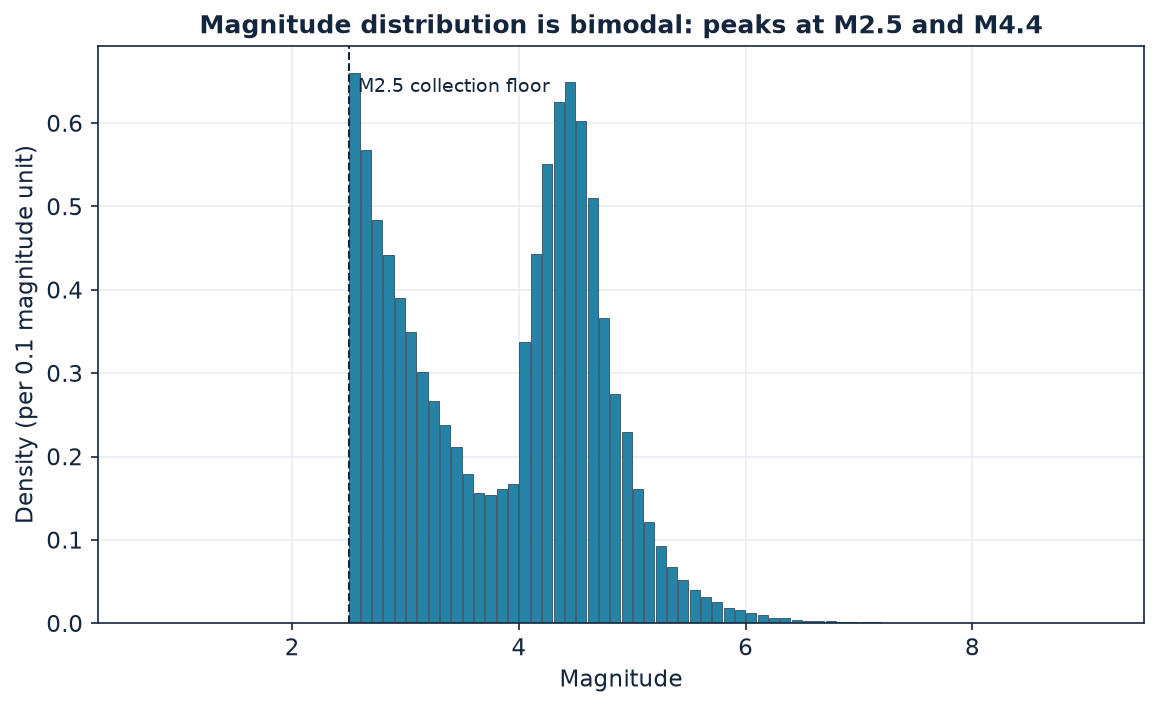

In [3]:
DM = 0.1
start = int(np.floor(mag.min() * 10))
stop = int(np.ceil(mag.max() * 10))
edges = np.arange(start, stop + 1) / 10.0
fm_counts, _ = np.histogram(mag, bins=edges)
fm_centers = (edges[:-1] + edges[1:]) / 2.0
nonzero = fm_counts > 0

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    fm_centers[nonzero],
    fm_counts[nonzero] / (len(mag) * DM),
    width=DM * 0.9,
    color=ACCENT,
    edgecolor=NAVY,
    linewidth=0.3,
)
ax.axvline(2.5, color=NAVY, linestyle="--", linewidth=1)
ax.text(2.58, ax.get_ylim()[1] * 0.92, "M2.5 collection floor", fontsize=9, color=NAVY)
ax.set_title("Magnitude distribution is bimodal: peaks at M2.5 and M4.4")
ax.set_xlabel("Magnitude")
ax.set_ylabel("Density (per 0.1 magnitude unit)")
save(fig, "eda_magnitude_distribution.png")
plt.close("all")

**What the shape says**

* The bulk of the catalog is small: mean **3.81**, median **4.00**, standard
  deviation **0.87**; 95% of events are M5.1 or smaller and only 0.06% reach M7+.
* The distribution is **not a single population**. One mode sits exactly at the M2.5
  collection floor (46,678 events in [2.5, 2.6)), and a second, almost equally tall
  mode sits at **M4.4** (45,939 events in [4.4, 4.5)), with a local minimum between
  them near M3.7–3.8 (10,879 events).
* The M2.5 mode is where *well-instrumented regional networks* are complete — they
  detect everything down to the query threshold. The M4.4 mode is where *global*
  detection saturates: outside dense networks, an earthquake must be about M4.4 to be
  reliably found and reported worldwide.
* A consequence: any single "completeness cutoff" quoted for this catalog has to say
  *which* population it refers to. Section 2 handles this explicitly.

## 2. Gutenberg-Richter law and the b-value

The Gutenberg-Richter relation states that the number of events of magnitude ≥ M
decays exponentially:

$$\log_{10} N(\ge M) = a - bM$$

where **b** describes the relative abundance of small versus large earthquakes; the
globally typical value is near **1.0**.

### Estimating completeness (MaxC)

**Maximum curvature (MaxC)** places Mc at the peak of the frequency-magnitude
histogram: the magnitude at which the catalog's counts stop rising and start falling
is taken as the point where detection becomes reliable. MaxC is a *lower bound* on
the true completeness magnitude — it systematically under-estimates Mc (see e.g.
Woessner & Wiemer, 2005) — so it is always safest to fit above it.

### Estimating b (maximum likelihood, Aki 1965)

For binned magnitudes with bin width Δm, the maximum-likelihood estimator is

$$b = \frac{\log_{10} e}{\bar{m} - M_c + \Delta m / 2}, \qquad \log_{10} e \approx 0.4343$$

applied to all events with $m \ge M_c$, and the sampling error is

$$\sigma_b \approx 2.30\, b^2 \sqrt{\frac{\sum_i (m_i - \bar m)^2}{N(N-1)}}$$

with $2.30 \approx \ln 10$ converting the natural-log derivation of the estimator to
base-10 units. **Formula choice:** we use exactly this binned-Aki expression (rather
than the continuous form) because the catalog reports magnitudes rounded to 0.1, and
the $+\Delta m/2$ term corrects for that binning. Note $\sigma_b$ is a *sampling*
error only — it shrinks like $1/\sqrt{N}$ and does **not** include the systematic
uncertainty from choosing Mc, which section 2.3 shows is much larger.

In [4]:
def aki_b(m, mc: float, dm: float = DM):
    """Aki (1965) binned maximum-likelihood b-value and its sampling error."""
    m = np.asarray(m, dtype=float)
    m = m[m >= mc]
    if len(m) < 2:
        return np.nan, np.nan, 0
    b = np.log10(np.e) / (m.mean() - mc + dm / 2)
    sigma = 2.30 * b**2 * np.sqrt(((m - m.mean()) ** 2).sum() / (len(m) * (len(m) - 1)))
    return b, sigma, len(m)


def max_c(m, dm: float = DM, lo: float | None = None):
    """Maximum-curvature Mc: lower edge of the highest bin of the FM histogram."""
    m = np.asarray(m, dtype=float)
    scale = int(round(1 / dm))  # 10 for dm = 0.1, so bin edges land on exact 0.1 values
    start = int(np.floor(m.min() * scale))
    stop = int(np.ceil(m.max() * scale))
    bin_edges = np.arange(start, stop + 1) / scale
    counts, _ = np.histogram(m, bins=bin_edges)
    centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0
    keep = counts > 0 if lo is None else (counts > 0) & (centers >= lo)
    idx = np.flatnonzero(keep)[np.argmax(counts[keep])]
    return bin_edges[idx], int(counts[idx])

### 2.1 MaxC on the whole catalog: Mc = 2.5 (the collection floor)

In [5]:
mc_full, peak_full = max_c(mag)
b_full, se_full, n_full = aki_b(mag, mc_full)
print(f"MaxC (full catalog)      : Mc = {mc_full}  (peak bin count {peak_full:,})")
print(f"Aki MLE for m >= {mc_full}    : b = {b_full:.4f} ± {se_full:.4f}  (N = {n_full:,})")

MaxC (full catalog)      : Mc = 2.5  (peak bin count 46,678)
Aki MLE for m >= 2.5    : b = 0.3190 ± 0.0002  (N = 707,433)


### 2.2 Diagnosing that estimate: the histogram has two completeness levels

A b-value of **0.32** is nowhere near the globally typical value of ~1.0 — the
estimate is not wrong arithmetically, it is answering the wrong question. The catalog
below M4.4 mixes two detection regimes:

In [6]:
step_lo = fm_counts[(fm_centers >= 3.9) & (fm_centers < 4.0)][0]
step_hi = fm_counts[(fm_centers >= 4.0) & (fm_centers < 4.1)][0]
valley_idx = np.flatnonzero((fm_centers >= 3.0) & (fm_centers < 4.4))
valley_center = fm_centers[valley_idx][np.argmin(fm_counts[valley_idx])]
valley_count = int(fm_counts[valley_idx].min())
mode2_mc, mode2_peak = max_c(mag, lo=3.8)

print(f"counts just below the M4.0 step: {step_lo:,} per 0.1 unit ([3.9, 4.0))")
print(f"counts just above the M4.0 step: {step_hi:,} per 0.1 unit ([4.0, 4.1))")
print(f"ratio: {step_hi / step_lo:.2f}x  (a reporting threshold at exactly M4.0)")
print(f"local minimum between the two modes: M{valley_center} ({valley_count:,} events)")
print(f"second mode: peak at M{mode2_mc} with {mode2_peak:,} events")

counts just below the M4.0 step: 11,859 per 0.1 unit ([3.9, 4.0))
counts just above the M4.0 step: 23,859 per 0.1 unit ([4.0, 4.1))
ratio: 2.01x  (a reporting threshold at exactly M4.0)
local minimum between the two modes: M3.75 (10,879 events)
second mode: peak at M4.4 with 45,939 events


### 2.3 MaxC of the globally complete mode: Mc = 4.4, and the headline b-value

Restricting MaxC to the second mode (bins above the M3.7–3.8 valley) puts Mc at
**M4.4**. Fitting Aki's estimator from there up uses the part of the catalog that is
complete everywhere on Earth:

In [7]:
mc_global, peak_global = max_c(mag, lo=3.8)
b_global, se_global, n_global = aki_b(mag, mc_global)

print(f"MaxC (second mode)        : Mc = {mc_global}  (peak bin count {peak_global:,})")
print(f"Aki MLE for m >= {mc_global}    : b = {b_global:.4f} ± {se_global:.4f}  (N = {n_global:,})")
print(f"95% interval              : [{b_global - 1.96 * se_global:.4f}, "
      f"{b_global + 1.96 * se_global:.4f}]")

sensitivity = []
for mc_test in [4.4, 4.5, 5.0, 5.5, 6.0]:
    b_t, se_t, n_t = aki_b(mag, mc_test)
    sensitivity.append(
        {"Mc": mc_test, "N": n_t, "b (MLE)": round(b_t, 3), "sigma_b": round(se_t, 4)}
    )
sensitivity.append({"Mc": "full (MaxC)", "N": n_full, "b (MLE)": round(b_full, 3),
                    "sigma_b": round(se_full, 4)})
print("\nMc sensitivity of the MLE estimate:")
print(pd.DataFrame(sensitivity).to_string(index=False))

MaxC (second mode)        : Mc = 4.4  (peak bin count 45,939)
Aki MLE for m >= 4.4    : b = 1.1013 ± 0.0022  (N = 234,532)
95% interval              : [1.0969, 1.1056]

Mc sensitivity of the MLE estimate:
         Mc      N  b (MLE)  sigma_b
        4.4 234532    1.101   0.0022
        4.5 188593    1.148   0.0027
        5.0  48246    1.100   0.0052
        5.5  13268    1.030   0.0090
        6.0   4001    1.017   0.0162
full (MaxC) 707433    0.319   0.0002


### 2.4 The frequency-magnitude plot

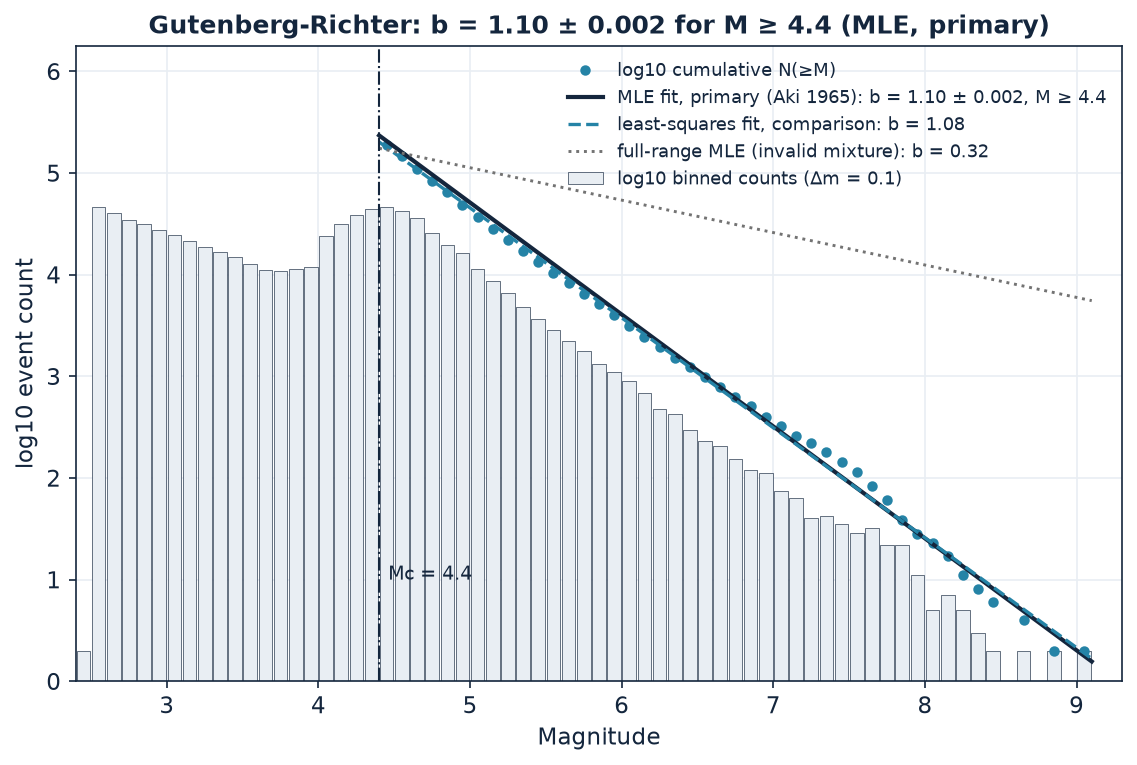

MLE  (primary) : b = 1.1013 ± 0.0022  for M >= 4.4
LSQ  (comparison): b = 1.0815  for M >= 4.4
full-range MLE : b = 0.3190 ± 0.0002  for M >= 2.5  <-- not usable


In [8]:
x_fit = np.array([mc_global, mag.max()])
n_at_mc = int((mag >= mc_global).sum())

# primary estimate: Aki MLE
y_mle = np.log10(n_at_mc) - b_global * (x_fit - mc_global)

# comparison: least-squares fit of log10 cumulative counts over the same range
cum_counts = np.array([(mag >= c).sum() for c in fm_centers])
cum_sel = nonzero & (fm_centers >= mc_global)
slope, intercept = np.polyfit(fm_centers[cum_sel], np.log10(cum_counts[cum_sel]), 1)
b_lsq = -slope
y_lsq = intercept + slope * x_fit

# cautionary line: MLE over the whole range (not a valid tectonic estimate)
n_all = len(mag)
y_full = np.log10(n_all) - b_full * (x_fit - mc_full)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(
    fm_centers[nonzero],
    np.log10(fm_counts[nonzero]),
    width=DM * 0.9,
    color=LIGHT,
    edgecolor=NAVY,
    linewidth=0.3,
    label="log10 binned counts (Δm = 0.1)",
)
ax.plot(
    fm_centers[cum_sel],
    np.log10(cum_counts[cum_sel]),
    "o",
    ms=4,
    color=ACCENT,
    label="log10 cumulative N(≥M)",
)
ax.plot(x_fit, y_mle, color=NAVY, lw=2,
        label=f"MLE fit, primary (Aki 1965): b = {b_global:.2f} ± {se_global:.3f}, M ≥ {mc_global}")
ax.plot(x_fit, y_lsq, color=ACCENT, lw=1.6, ls="--",
        label=f"least-squares fit, comparison: b = {b_lsq:.2f}")
ax.plot(x_fit, y_full, color="0.45", lw=1.4, ls=":",
        label=f"full-range MLE (invalid mixture): b = {b_full:.2f}")
ax.axvline(mc_global, color=NAVY, lw=1, ls="-.")
ax.text(mc_global + 0.06, 1.0, f"Mc = {mc_global}", fontsize=9, color=NAVY)
ax.set_xlim(2.4, mag.max() + 0.2)
ax.set_ylim(0, np.log10(n_all) + 0.4)
ax.set_title(
    f"Gutenberg-Richter: b = {b_global:.2f} ± {se_global:.3f} for M ≥ {mc_global} "
    "(MLE, primary)"
)
ax.set_xlabel("Magnitude")
ax.set_ylabel("log10 event count")
ax.legend(fontsize=8.5, loc="upper right")
save(fig, "eda_gutenberg_richter.png")
plt.close("all")

print(f"MLE  (primary) : b = {b_global:.4f} ± {se_global:.4f}  for M >= {mc_global}")
print(f"LSQ  (comparison): b = {b_lsq:.4f}  for M >= {mc_global}")
print(f"full-range MLE : b = {b_full:.4f} ± {se_full:.4f}  for M >= {mc_full}  <-- not usable")

**Is the b-value consistent with the globally typical value near 1.0?**

* The **primary** estimate — Aki MLE over the globally complete range — is
  **b = 1.10 ± 0.002** (N = 234,532, M ≥ 4.4). It is statistically distinguishable
  from exactly 1.0 because N is enormous, but it sits inside the range of b-values
  routinely observed across tectonic settings (≈ 0.8–1.2) and is the right order of
  magnitude for a global catalog.
* The estimate is **sensitive to Mc**, more so than the tiny σ_b suggests: Mc = 4.5
  gives 1.15, Mc = 5.0 gives 1.10, Mc = 6.0 gives 1.02, and a least-squares fit over
  the same range gives 1.08. All of these are "near 1.0" in seismological terms; the
  naive full-range value of **0.32** is not, and that contrast is the real finding.
* Why the full range fails: below M4.4 the sample mixes regional networks (complete
  to the M2.5 floor) with global detection (complete only near M4.4). The result is a
  non-monotonic frequency-magnitude curve — visible as the step at exactly M4.0, where
  counts jump 2.0× — which no single exponential can describe.
* **Reporting convention used from here on:** `b = 1.10 ± 0.002 (M ≥ 4.4)`, with the
  Mc-sensitivity range 1.02–1.15 quoted alongside it.

### 2.5 Comparing b across time periods

Time is the most defensible axis for comparison with this data: the magnitude
threshold can be held fixed (M ≥ 5.0, complete in every era of the catalog) instead of
relying on region labels parsed from free text. Each point is a two-year period; error
bars are the sampling error from the same Aki expression.

In [9]:
df = df.assign(period=(df["year"] // 2) * 2)

rows = []
for period, group in df.groupby("period"):
    b_a, se_a, n_a = aki_b(group["mag"].to_numpy(), 4.4)
    b_b, se_b, n_b = aki_b(group["mag"].to_numpy(), 5.0)
    rows.append(
        {
            "period": f"{period}–{period + 1}",
            "N (M≥4.4)": n_a,
            "b (M≥4.4)": b_a,
            "se (M≥4.4)": se_a,
            "N (M≥5.0)": n_b,
            "b (M≥5.0)": b_b,
            "se (M≥5.0)": se_b,
        }
    )
periods = pd.DataFrame(rows)
print(periods.round(3).to_string(index=False))

   period  N (M≥4.4)  b (M≥4.4)  se (M≥4.4)  N (M≥5.0)  b (M≥5.0)  se (M≥5.0)
2000–2001      11703      0.965       0.009       2843      0.920       0.016
2002–2003      12170      1.012       0.009       2675      0.922       0.016
2004–2005      17290      1.080       0.008       3514      1.010       0.016
2006–2007      17520      1.023       0.007       4165      1.126       0.018
2008–2009      14696      0.960       0.007       4037      1.154       0.020
2010–2011      19648      0.964       0.006       5098      1.169       0.018
2012–2013      17261      1.094       0.008       3308      1.105       0.021
2014–2015      19612      1.203       0.009       3320      1.062       0.019
2016–2017      17565      1.172       0.009       3272      1.129       0.021
2018–2019      18547      1.166       0.008       3413      1.130       0.020
2020–2021      19747      1.178       0.008       3677      1.152       0.020
2022–2023      20027      1.219       0.009       3505      1.11

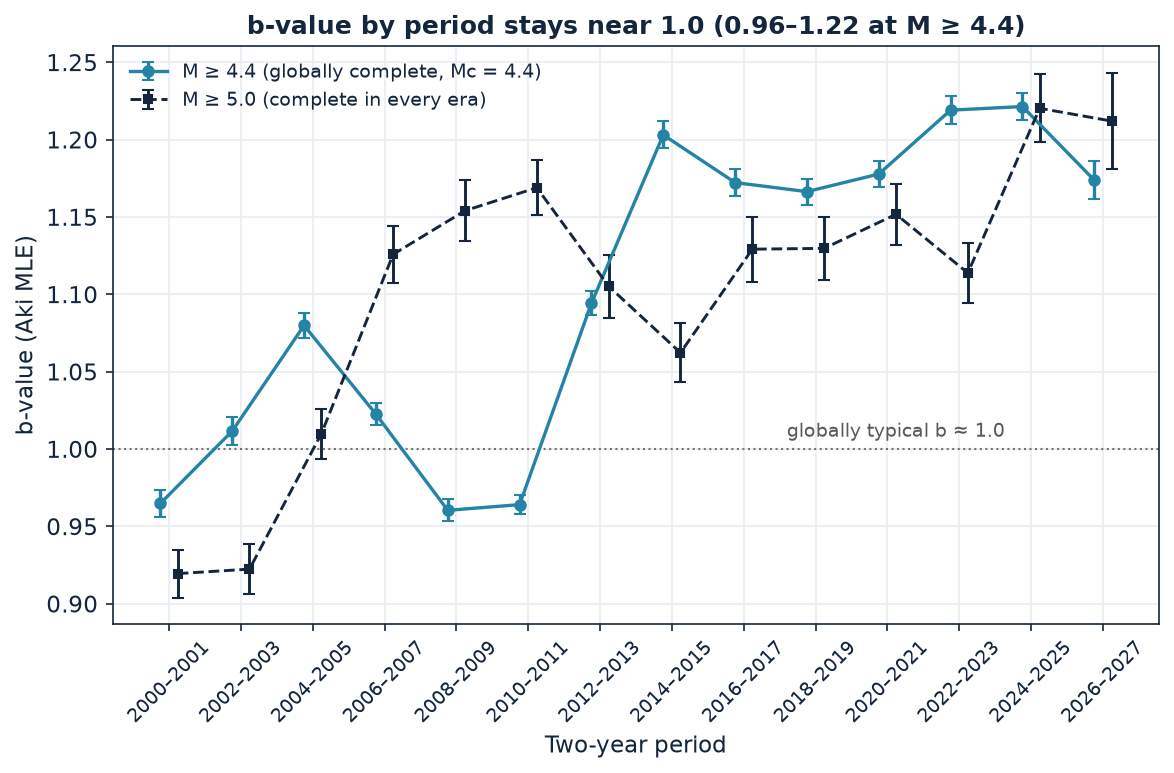

b(M≥4.4) range: 0.960 – 1.221


In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(periods))
ax.errorbar(x - 0.12, periods["b (M≥4.4)"], yerr=periods["se (M≥4.4)"],
            fmt="o-", ms=5, lw=1.6, color=ACCENT, capsize=3,
            label="M ≥ 4.4 (globally complete, Mc = 4.4)")
ax.errorbar(x + 0.12, periods["b (M≥5.0)"], yerr=periods["se (M≥5.0)"],
            fmt="s--", ms=4, lw=1.4, color=NAVY, capsize=3,
            label="M ≥ 5.0 (complete in every era)")
ax.axhline(1.0, color="0.45", lw=1, ls=":")
ax.text(8.6, 1.008, "globally typical b ≈ 1.0", fontsize=9, color="0.35")
ax.set_xticks(x)
ax.set_xticklabels(periods["period"], rotation=45, fontsize=9)
ax.set_title("b-value by period stays near 1.0 (0.96–1.22 at M ≥ 4.4)")
ax.set_ylabel("b-value (Aki MLE)")
ax.set_xlabel("Two-year period")
ax.legend(fontsize=9)
save(fig, "eda_bvalue_by_period.png")
plt.close("all")

print(
    "b(M≥4.4) range: "
    f"{periods['b (M≥4.4)'].min():.3f} – {periods['b (M≥4.4)'].max():.3f}"
)

**Reading the period comparison.** b-values computed at M ≥ 4.4 rise from
**0.97 (2000–2001)** to **1.22 (2024–2025)**, while the M ≥ 5.0 series (complete
everywhere, less sensitive to reporting practice) stays between **0.92 and 1.22** and
hovers near 1.1 for most of the record. Two cautions:

* the early-period values sit low partly because small-magnitude detection was poorer
  then — an incompleteness effect, not necessarily a change in tectonics;
* with N in the thousands, the sampling errors are small, so apparent period-to-period
  differences are real *for this catalog* but mix genuine variability with changes in
  how the catalog was assembled.

Per-region b-values at the same M ≥ 4.4 threshold (computed in section 5) scatter
around the same value — that comparison belongs with the regional view below.

## 3. Temporal trends

In [11]:
monthly = df.set_index("time").sort_index().resample("ME").size()
rolling = monthly.rolling(12).mean()
yearly = df.groupby("year").size()

print(f"months: {len(monthly)}  ({monthly.index[0].date()} … {monthly.index[-1].date()})")
print(f"busiest month: {monthly.max():,} ({monthly.idxmax().date()})")
print(f"quietest full month: {monthly['2000':'2026-10'].min():,} "
      f"({monthly['2000':'2026-10'].idxmin().date()})")
print(f"12-month rolling mean: {rolling.dropna().iloc[0]:,.0f}/month "
      f"→ {rolling['2000':'2026-10'].dropna().iloc[-1]:,.0f}/month")
print(f"yearly counts: {yearly.loc[2000]:,} (2000) → {yearly.loc[2025]:,} (2025), "
      f"ratio {yearly.loc[2025] / yearly.loc[2000]:.2f}×")

months: 323  (2000-01-31 … 2026-11-30)
busiest month: 7,636 (2018-07-31)
quietest full month: 1,104 (2009-12-31)
12-month rolling mean: 1,487/month → 2,462/month
yearly counts: 17,847 (2000) → 29,063 (2025), ratio 1.63×


monthly counts for the annotated events:
  2004 Sumatra M9.1: 2,912 events in 2004-12
  2010 Haiti M7.0: 1,436 events in 2010-01
  2011 Tōhoku M9.1: 4,251 events in 2011-03
  2023 Türkiye M7.8: 2,297 events in 2023-02


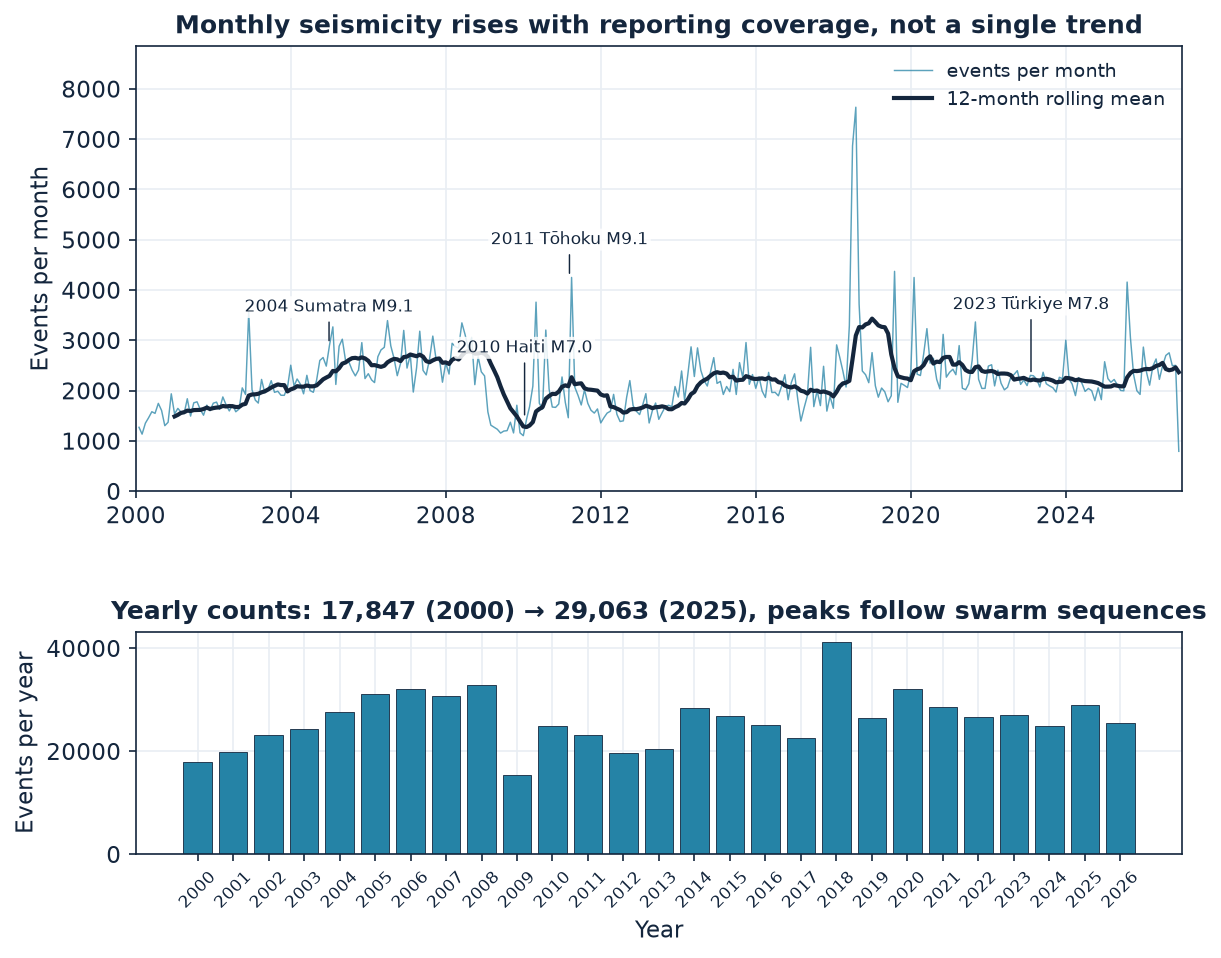

In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=False,
                               gridspec_kw={"height_ratios": [2, 1], "hspace": 0.42})

ax1.plot(monthly.index, monthly.values, color=ACCENT, lw=0.7, alpha=0.75,
         label="events per month")
ax1.plot(rolling.index, rolling.values, color=NAVY, lw=2, label="12-month rolling mean")

annotations = [
    ("2004-12-26", "2004 Sumatra M9.1"),
    ("2010-01-12", "2010 Haiti M7.0"),
    ("2011-03-11", "2011 Tōhoku M9.1"),
    ("2023-02-06", "2023 Türkiye M7.8"),
]
counts_by_month = {stamp.strftime("%Y-%m"): int(val) for stamp, val in monthly.items()}
print("monthly counts for the annotated events:")
for date, label in annotations:
    key = pd.Timestamp(date, tz="UTC").strftime("%Y-%m")
    print(f"  {label}: {counts_by_month[key]:,} events in {key}")
for i, (date, label) in enumerate(annotations):
    ts = pd.Timestamp(date, tz="UTC")
    y = counts_by_month[ts.strftime("%Y-%m")]
    ax1.annotate(
        label,
        xy=(ts, y),
        xytext=(0, 16 + 16 * (i % 2)),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color=NAVY,
        bbox={"boxstyle": "round,pad=0.15", "facecolor": "white",
              "edgecolor": "none", "alpha": 0.85},
        arrowprops={"arrowstyle": "-", "color": NAVY, "lw": 0.7},
    )

ax1.set_title("Monthly seismicity rises with reporting coverage, not a single trend")
ax1.set_ylabel("Events per month")
ax1.legend(fontsize=9, loc="upper right")
ax1.set_xlim(pd.Timestamp("2000-01-01", tz="UTC"), pd.Timestamp("2026-12-31", tz="UTC"))
ax1.set_ylim(0, monthly.max() * 1.16)

ax2.bar(yearly.index.astype(str), yearly.values, color=ACCENT, edgecolor=NAVY, linewidth=0.4)
ax2.set_title(f"Yearly counts: {yearly.loc[2000]:,} (2000) → {yearly.loc[2025]:,} (2025), "
              "peaks follow swarm sequences")
ax2.set_ylabel("Events per year")
ax2.set_xlabel("Year")
ax2.tick_params(axis="x", rotation=45, labelsize=8)
save(fig, "eda_temporal_trends.png")
plt.close("all")

**Critical caveat — do not read this as "earthquakes are increasing".**

The catalog records **17,847** events in 2000 and **29,063** in 2025 (+63%), and the
12-month rolling mean climbs from **1,487** to **2,462 events/month**. But the
number of events a catalog *contains* is the product of seismicity **and** the
probability that an event is detected, located and reported. Over these 26 years that
probability rose: more stations, more automatic processing, more networks reporting
into ComCat, and lower thresholds for small events in well-instrumented regions.
The catalog's completeness is **not constant across 26 years**, so a rising count
series is at least partly an instrument record, not a tectonic one. A rise like this
must never be presented as evidence that Earth is getting more seismic without first
controlling for coverage — which this project does not claim to do.

Genuine features that are *not* coverage effects are the **spikes**: the busiest month
on record is **July 2018 (7,636 events)**, dominated by the Kīlauea lower-rift
eruption sequence in Hawaii, and **March 2011 (4,251)** follows the M9.1 Tōhoku
earthquake and its aftershock sequence. Annotated events: 2004 Sumatra M9.1,
2010 Haiti M7.0, 2011 Tōhoku M9.1, 2023 Türkiye M7.8.

## 4. Depth profile

In [13]:
depth = df["depth"]
neg_depth = depth[depth < 0]
deep = depth[depth > 300]
print(f"depth: median {depth.median():.1f} km, mean {depth.mean():.1f} km, "
      f"range {depth.min():.2f} – {depth.max():.1f} km")
print(f"negative depths: {len(neg_depth):,} ({100 * len(neg_depth) / len(depth):.2f}%), "
      f"shallowest {depth.min():.2f} km")
print(f"≤ 35 km: {(depth <= 35).sum():,} ({100 * (depth <= 35).mean():.1f}%)")
print(f"≤ 70 km: {(depth <= 70).sum():,} ({100 * (depth <= 70).mean():.1f}%)")
print(f"> 300 km: {len(deep):,} ({100 * len(deep) / len(depth):.2f}%), "
      f"deepest {depth.max():.1f} km")
print(f"events at exactly 300 km (fixed-depth solutions): {(depth == 300).sum():,}")
print("\ntop regions among events deeper than 300 km:")
print(region[deep.index].value_counts().head(5).to_string())

depth: median 20.4 km, mean 56.7 km, range -3.74 – 735.8 km
negative depths: 4,359 (0.62%), shallowest -3.74 km
≤ 35 km: 476,390 (67.3%)
≤ 70 km: 566,339 (80.1%)
> 300 km: 26,960 (3.81%), deepest 735.8 km
events at exactly 300 km (fixed-depth solutions): 228

top regions among events deeper than 300 km:
place
south of the Fiji Islands    5965
Fiji                         4990
Fiji region                  4947
Tonga                        2071
Japan region                 1328


depth by magnitude bin:
magnitude bin  events  q10 (km)  median (km)  q90 (km)  % > 300 km
      2.5–3.0  179919       1.4         10.0      69.1         0.0
      3.0–3.5   96721       4.0         15.0      80.0         0.2
      3.5–4.0   57830       5.0         24.1     135.5         2.7
      4.0–4.5  184370      10.0         35.0     254.2         9.0
      4.5–5.0  140347      10.0         31.6     154.6         4.9
      5.0–5.5   34978      10.0         24.2     109.9         2.8
      5.5–6.0    9267      10.0         20.0     139.4         5.4
      6.0–6.5    2777      10.0         21.0     179.5         6.5
      6.5–7.0     824      10.0         22.9     355.9        10.6
      7.0–7.5     256      10.0         33.0     338.8        10.2
      7.5–8.0     116      10.0         30.5     270.0         9.5

events below M3.5: 276,645; deeper than 300 km: 163 (0.06%)


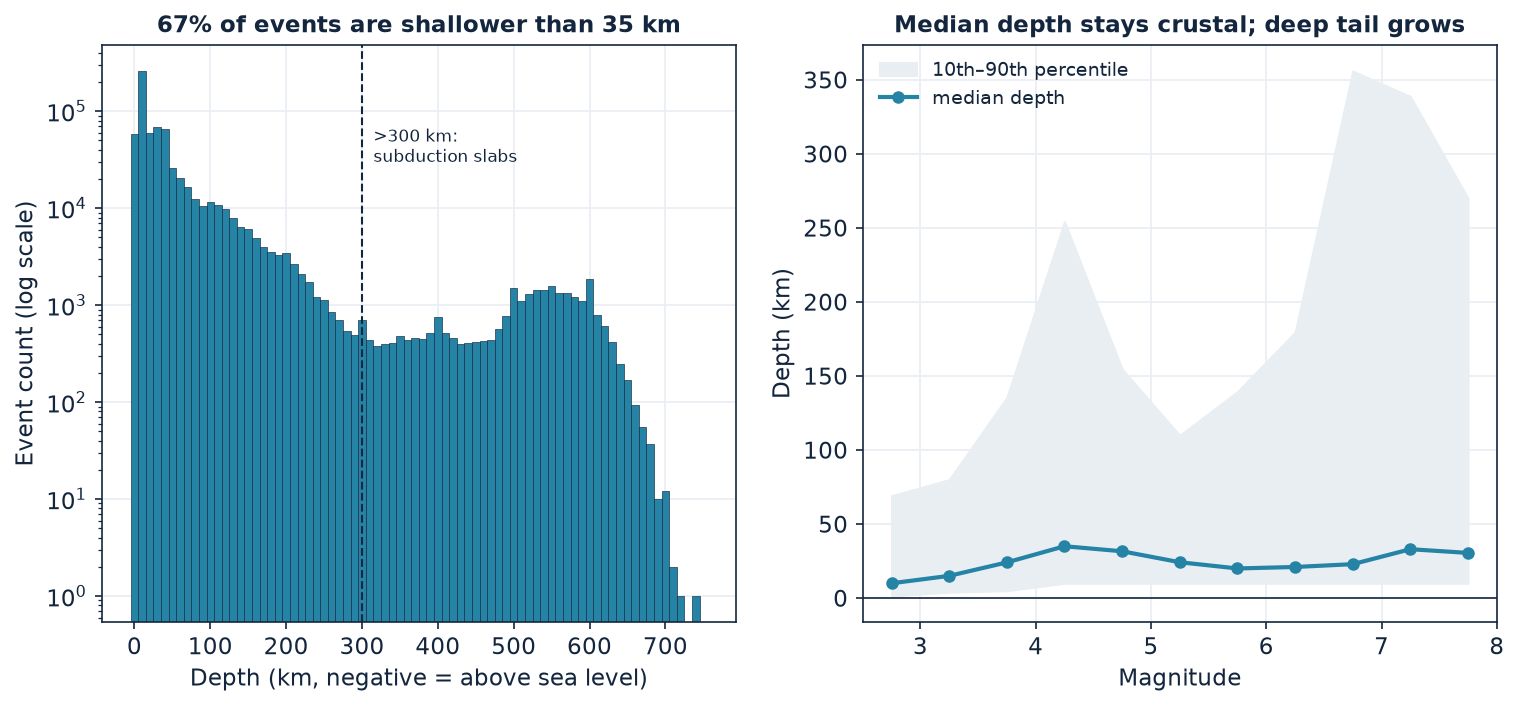

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

depth_edges = np.arange(-5, 760, 10)
ax1.hist(depth, bins=depth_edges, color=ACCENT, edgecolor=NAVY, linewidth=0.3)
ax1.set_yscale("log")
ax1.axvline(300, color=NAVY, ls="--", lw=1)
ax1.text(315, 3e4, ">300 km:\nsubduction slabs", fontsize=8, color=NAVY)
ax1.set_title("67% of events are shallower than 35 km", fontsize=11)
ax1.set_xlabel("Depth (km, negative = above sea level)")
ax1.set_ylabel("Event count (log scale)")

mag_bins = np.arange(2.5, 8.01, 0.5)
mag_idx = np.digitize(mag, mag_bins) - 1
medians, q10s, q90s, mids, ns, deep_pct = [], [], [], [], [], []
for i in range(len(mag_bins) - 1):
    sel = mag_idx == i
    if sel.sum() < 50:
        continue
    d = depth.to_numpy()[sel]
    medians.append(np.median(d))
    q10s.append(np.percentile(d, 10))
    q90s.append(np.percentile(d, 90))
    mids.append((mag_bins[i] + mag_bins[i + 1]) / 2)
    ns.append(int(sel.sum()))
    deep_pct.append(100 * (d > 300).mean())

depth_by_mag = pd.DataFrame(
    {
        "magnitude bin": [f"{m - 0.25:.1f}–{m + 0.25:.1f}" for m in mids],
        "events": ns,
        "q10 (km)": np.round(q10s, 1),
        "median (km)": np.round(medians, 1),
        "q90 (km)": np.round(q90s, 1),
        "% > 300 km": np.round(deep_pct, 1),
    }
)
print("depth by magnitude bin:")
print(depth_by_mag.to_string(index=False))

below_35 = df.loc[df["mag"] < 3.5, "depth"]
print(f"\nevents below M3.5: {len(below_35):,}; deeper than 300 km: "
      f"{int((below_35 > 300).sum()):,} ({100 * (below_35 > 300).mean():.2f}%)")

ax2.fill_between(mids, q10s, q90s, color=LIGHT, label="10th–90th percentile")
ax2.plot(mids, medians, "o-", color=ACCENT, lw=2, ms=5, label="median depth")
ax2.axhline(0, color=NAVY, lw=0.8)
ax2.set_title("Median depth stays crustal; deep tail grows", fontsize=11)
ax2.set_xlabel("Magnitude")
ax2.set_ylabel("Depth (km)")
ax2.legend(fontsize=9)
save(fig, "eda_depth_profile.png")
plt.close("all")

**Interpretation.**

* **67.3%** of events are shallower than 35 km — the crustal population where most
  damaging earthquakes occur — and **80.1%** are shallower than 70 km (the typical
  depth of plate boundaries).
* The **4,359 negative depths** (0.62%, shallowest −3.74 km) are near-surface events
  above sea level; they are retained (notebook 02) and appear in the first histogram
  bin.
* The tail beyond **300 km (26,960 events, 3.81%)** is not noise: those are
  subducting slabs — most of them under Fiji (5,965 "south of the Fiji Islands" +
  4,990 "Fiji" + 4,947 "Fiji region"), Tonga (2,071) and the Japan region (1,328) —
  with the deepest at **735.8 km**.
* Depth does **not** grow monotonically with magnitude: the median stays between
  10 and 35 km in every magnitude bin, while the deep tail expands — the 90th
  percentile runs from **69 km** at M2.5–3.0 to **356 km** at M6.5–7.0.
* Deep events are strongly depleted at small magnitudes: only **163 of 276,645**
  events below M3.5 (0.06%) are deeper than 300 km, against **9.0%** of M4.0–4.5
  events. That is a detection statement as much as a geological one: absence of
  records is not absence of seismicity.

## 5. Most-active regions

The region label is derived **once** in the setup cell at the top of this notebook
(so the depth analysis in section 4 and the regional view here use exactly the same
labels). The rules: take the text after the final comma of `place`; if there is no
comma, keep the whole string; if `place` is missing or the segment is empty, label it
`(unlabeled)`.

In [15]:
region_counts = region.value_counts()
print(f"distinct region labels: {len(region_counts)}")
print(f"events without a comma in place (kept whole string): "
      f"{int((~has_comma & place.notna()).sum()):,}")
print(f"missing/empty place labels: {int(region.eq('(unlabeled)').sum())}")
print("\ntop 15 regions:")
print(region_counts.head(15).to_string())

distinct region labels: 741
events without a comma in place (kept whole string): 78,356
missing/empty place labels: 1

top 15 regions:
place
Alaska              122898
Indonesia            45822
Puerto Rico          29362
Chile                28989
Japan                27137
Greece               22411
Hawaii               20282
Papua New Guinea     20145
CA                   18600
Philippines          17004
Russia               15334
Mexico               15114
Tonga                12875
California           12231
New Zealand          11056


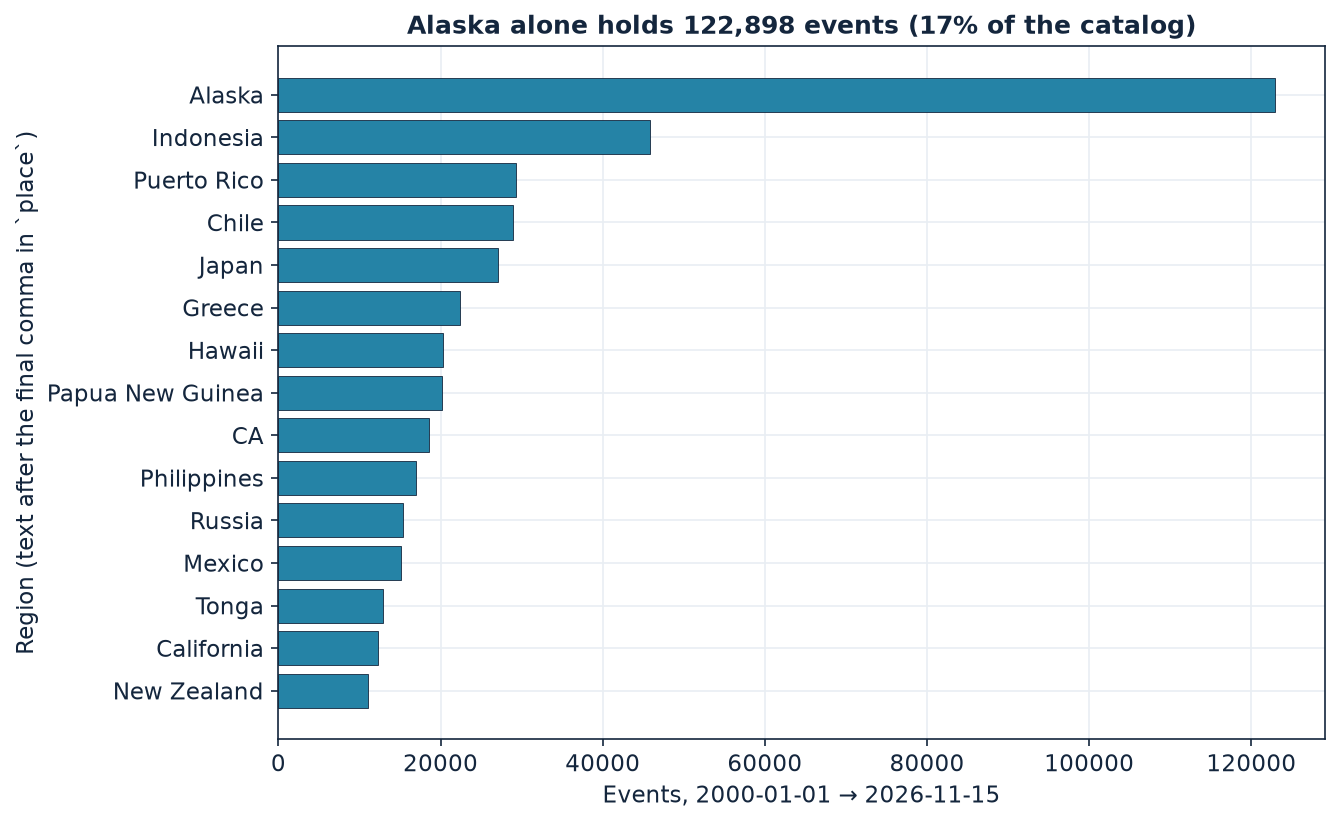

In [16]:
top = region_counts.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=ACCENT, edgecolor=NAVY, linewidth=0.4)
ax.set_title(f"Alaska alone holds {top.max():,} events "
             f"({100 * region_counts.iloc[0] / len(df):.0f}% of the catalog)")
ax.set_xlabel("Events, 2000-01-01 → 2026-11-15")
ax.set_ylabel("Region (text after the final comma in `place`)")
save(fig, "eda_top_regions.png")
plt.close("all")

In [17]:
b_rows = []
for reg in region_counts.head(15).index:
    b_reg, se_reg, n_reg = aki_b(df.loc[df["region"] == reg, "mag"].to_numpy(), mc_global)
    if n_reg >= 500:
        b_rows.append(
            {"region": reg, "N (M≥4.4)": n_reg, "b": round(b_reg, 3),
             "sigma_b": round(se_reg, 3)}
        )
region_b = pd.DataFrame(b_rows)
print("b-value per region for M ≥ 4.4 (globally complete range):")
print(region_b.to_string(index=False))

b-value per region for M ≥ 4.4 (globally complete range):
          region  N (M≥4.4)     b  sigma_b
          Alaska       5176 0.950    0.013
       Indonesia      28399 1.112    0.006
           Chile       8230 1.081    0.012
           Japan      16552 1.151    0.009
          Greece       2244 1.345    0.031
Papua New Guinea      13111 1.025    0.008
     Philippines      12015 1.208    0.011
          Russia       8558 1.134    0.012
          Mexico       3424 1.063    0.020
           Tonga       9529 1.035    0.009
     New Zealand       5105 1.120    0.015


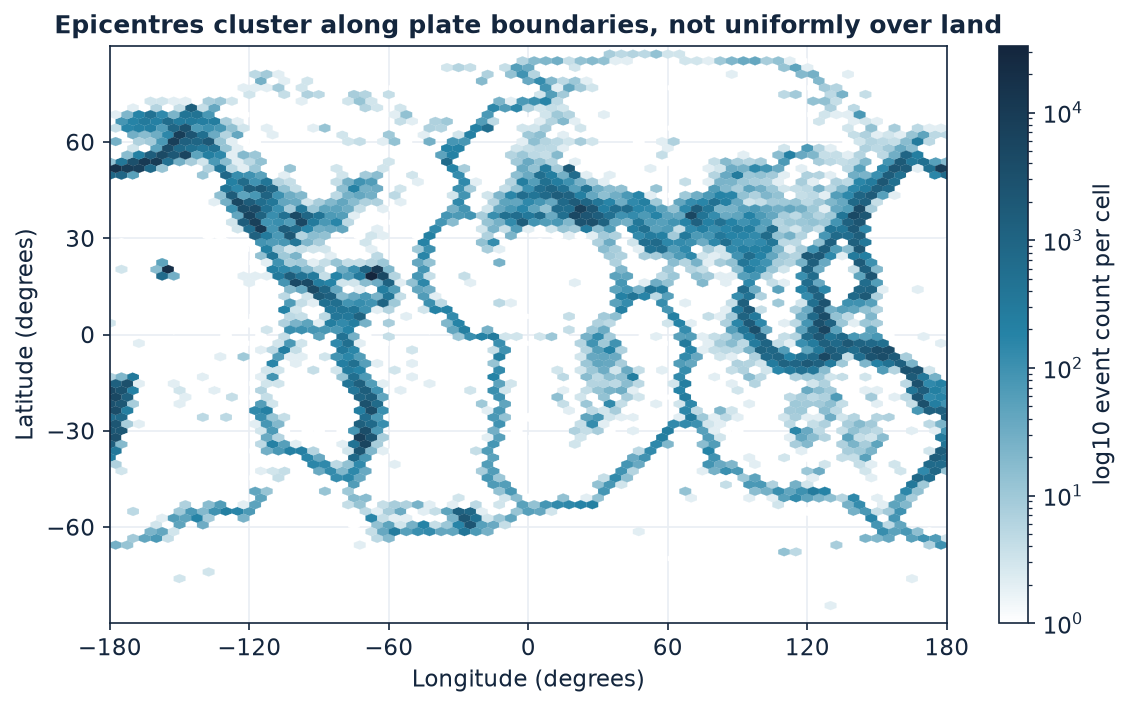

In [18]:
cmap = LinearSegmentedColormap.from_list("seismo", ["#FFFFFF", ACCENT, NAVY])
fig, ax = plt.subplots(figsize=(9, 5))
hb = ax.hexbin(
    df["longitude"],
    df["latitude"],
    gridsize=72,
    bins="log",
    cmap=cmap,
    mincnt=1,
    linewidths=0.1,
)
cb = fig.colorbar(hb, ax=ax)
cb.set_label("log10 event count per cell")
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_title("Epicentres cluster along plate boundaries, not uniformly over land")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_xticks([-180, -120, -60, 0, 60, 120, 180])
ax.set_yticks([-60, -30, 0, 30, 60])
save(fig, "eda_spatial_density.png")
plt.close("all")

**Caveats for the regional view.**

* The label is the text **after the final comma** of the USGS `place` string
  (`"3 km N of Cairo, Egypt"` → `"Egypt"`); 11.1% of places (78,356) have no comma at
  all and are kept whole, and 1 row has no place (labelled `(unlabeled)`).
* Labels are **verbatim**, so USGS's own inconsistencies show through: `CA`
  (18,600 events, from networks using the two-letter suffix) and `California`
  (12,231) are the same state listed under two spellings, and oceanic events carry
  descriptive labels such as `"south of the Fiji Islands"`.
* **High counts partly reflect monitoring density.** Alaska (122,898 events, 17.4%)
  and Puerto Rico (29,362) are intensely instrumented; a region with no events in
  this chart may simply lack stations. Absence of records ≠ absence of seismicity.
* The hexbin view has the same bias in map form: bright corridors mark where stations
  exist as much as where fault slip occurs.

## 6. Conclusions

1. **Catalog.** 707,438 earthquakes from 2000-01-01 to 2026-11-15 (M0.7–9.1,
   depth −3.74 to 735.8 km), reduced from 715,183 raw rows by removing 7,745
   non-earthquake events and 0 duplicate ids.
2. **Magnitudes.** Mean 3.81, median 4.00, σ = 0.87; 95% of events are ≤ M5.1. The
   distribution is **bimodal** — 46,678 events in [2.5, 2.6) at the collection floor
   and 45,939 in [4.4, 4.5) at the global detection ceiling, with a valley of 10,879
   events near M3.75.
3. **Completeness and b-value.** MaxC on the full histogram gives Mc = 2.5 (pinned to
   the query floor); MaxC of the globally complete mode gives **Mc = 4.4**. The
   headline estimate is **b = 1.10 ± 0.002 (Aki MLE, N = 234,532, M ≥ 4.4)**, with an
   Mc-sensitivity range of 1.02–1.15 and a least-squares cross-check of 1.08 —
   consistent with the globally typical value near 1.0.
4. **Why the naive estimate fails.** Fitting the whole range at Mc = 2.5 yields
   b = 0.32 ± 0.00 because regional and global detection regimes are mixed; the
   frequency-magnitude curve jumps 2.0× at exactly M4.0.
5. **Time.** Yearly counts rise 17,847 (2000) → 29,063 (2025), +63%, and the
   12-month rolling mean rises 1,487 → 2,462 events/month — a trend that **may reflect
   improving detection/reporting coverage rather than increased seismicity**; spikes
   (July 2018: 7,636, Kīlauea; March 2011: 4,251, Tōhoku aftershocks) are the
   trustworthy features. b by period: 0.97 (2000–2001) → 1.22 (2024–2025).
6. **Depth.** Median 20.4 km; 67.3% ≤ 35 km and 80.1% ≤ 70 km; 4,359 negative
   near-surface depths retained; 26,960 events (3.81%) deeper than 300 km, mostly
   Fiji–Tonga–Japan slabs, deepest 735.8 km.
7. **Regions.** 741 distinct labels; top three are **Alaska (122,898, 17.4%)**,
   **Indonesia (45,822)** and **Puerto Rico (29,362)** — high counts partly reflect
   monitoring density, so this is a map of recorded activity, not of hazard.
8. **Stance.** All of the above describe *history*. They support probability
   statements about populations of earthquakes, not predictions of individual
   events — and historical activity is not disaster risk.